# 🎬 Movie Recommendation System — Popularity, Collaborative Filtering, Matrix Factorization & Content-Based

**Goal:** recommend movies a user is likely to watch and enjoy next, and compare the main families of recommender algorithms on **real ratings** using NumPy, SciPy (sparse matrices, `svds`) and scikit-learn.

**Dataset: [MovieTweetings](https://github.com/sidooms/MovieTweetings)** (100K snapshot, MIT licence). These are real IMDb ratings on a 0–10 scale that users posted publicly on Twitter (Feb–Sep 2013). The data is very sparse, like real product catalogues.

**What's inside**
1. Data loading, k-core filtering and sparsity analysis
2. **Time-aware** train / validation / test split, so we always predict the *future* from the *past*
3. Rating prediction: global mean, regularised user and item biases, and SVD matrix factorization (RMSE / MAE)
4. Top-N recommendation: popularity, item-based and user-based collaborative filtering, PureSVD, content-based (TF-IDF genres) and a hybrid
5. Ranking metrics (HitRate, Precision, Recall, NDCG @10) plus **catalogue coverage** and **novelty**, because beyond accuracy, recommendations should not all be the same blockbusters
6. Hyper-parameter tuning on the validation split only, and a cold-start analysis
7. Demo: "Because you liked …" recommendations and similar-movie search

*Author: Priyadharshini Sivasankar · MSc Data Science*

In [1]:
import warnings, os, re
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

SEED = 42
rng = np.random.default_rng(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
PAL = ["#94a3b8", "#2563eb", "#16a34a", "#f97316", "#7c3aed", "#dc2626", "#0891b2"]
print("Libraries loaded.")

Libraries loaded.


## 1. Load the data
The data files are included in `data/`. If they are missing, the notebook downloads them from the MovieTweetings GitHub repository.

In [2]:
BASE = "https://raw.githubusercontent.com/sidooms/MovieTweetings/master/snapshots/100K/"
def load(name, cols):
    path = f"data/{name}"
    src = path if os.path.exists(path) else BASE + name
    return pd.read_csv(src, sep="::", engine="python", names=cols, encoding="utf-8")
ratings = load("ratings.dat", ["user_id", "movie_id", "rating", "ts"])
movies = load("movies.dat", ["movie_id", "title", "genres"])
movies["genres"] = movies.genres.fillna("")
movies["year"] = movies.title.str.extract(r"\((\d{4})\)\s*$").astype(float)
ratings["time"] = pd.to_datetime(ratings.ts, unit="s")
print(f"Ratings: {len(ratings):,} | users: {ratings.user_id.nunique():,} | movies: {ratings.movie_id.nunique():,}")
print(f"Period: {ratings.time.min():%d %b %Y} – {ratings.time.max():%d %b %Y} | scale 0–10, mean {ratings.rating.mean():.2f}")
dens = len(ratings) / (ratings.user_id.nunique() * ratings.movie_id.nunique())
print(f"Matrix density: {dens:.5%}  (i.e. {1 - dens:.3%} of user–movie pairs are unknown)")
display(ratings.merge(movies, on="movie_id").sort_values("time").head(5)[["user_id", "title", "genres", "rating", "time"]])

Ratings: 100,000 | users: 16,554 | movies: 10,506
Period: 28 Feb 2013 – 01 Sep 2013 | scale 0–10, mean 7.32
Matrix density: 0.05750%  (i.e. 99.943% of user–movie pairs are unknown)


,user_id,title,genres,rating,time
76310,12620,Dead Mine (2012),Action|Horror,6,2013-02-28 14:38:27
46217,7527,Mah nakorn (2004),Comedy|Fantasy|Romance,8,2013-02-28 14:43:44
48939,7913,No Strings Attached (2011),Comedy|Romance,6,2013-02-28 14:47:18
24228,3901,The Paperboy (2012),Thriller,7,2013-02-28 14:58:23
51452,8321,La vita è bella (1997),Comedy|Drama|Romance|War,5,2013-02-28 15:00:53


## 2. Exploratory analysis: a long-tail, very sparse problem

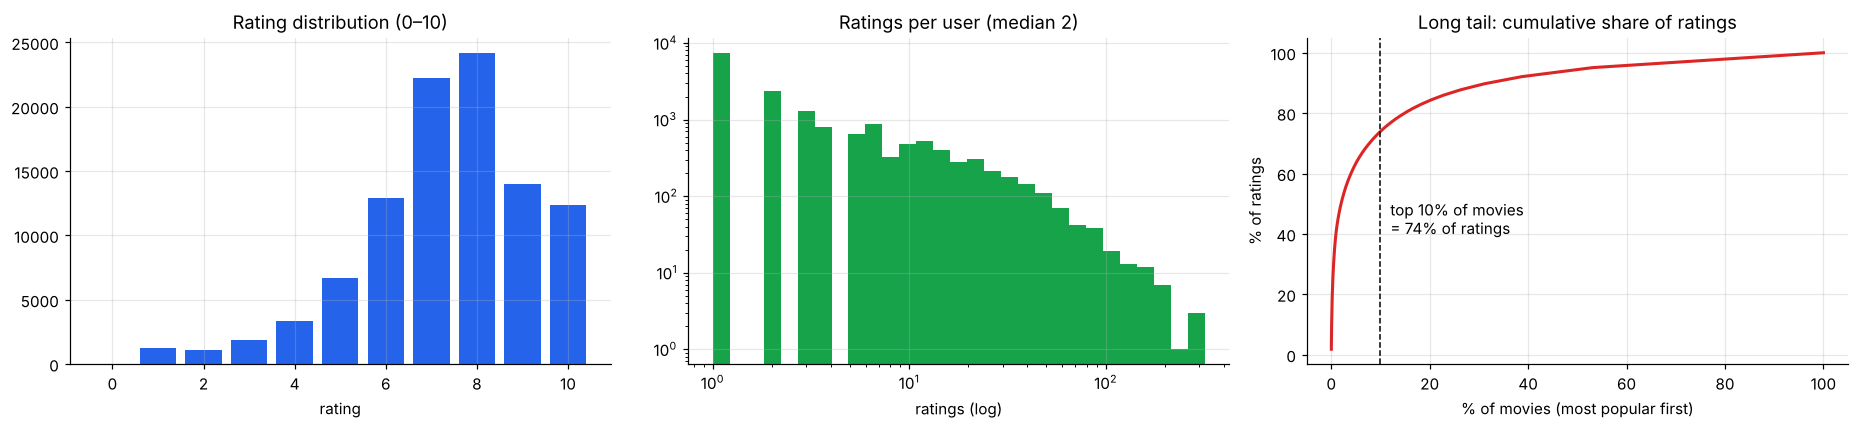

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
rc = ratings.rating.value_counts().sort_index()
axes[0].bar(rc.index, rc.values, color="#2563eb"); axes[0].set_title("Rating distribution (0–10)"); axes[0].set_xlabel("rating")
upc = ratings.user_id.value_counts()
axes[1].hist(upc, bins=np.logspace(0, np.log10(upc.max()), 30), color="#16a34a"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title(f"Ratings per user (median {int(upc.median())})"); axes[1].set_xlabel("ratings (log)")
ipc = ratings.movie_id.value_counts().values
axes[2].plot(np.arange(1, len(ipc) + 1) / len(ipc) * 100, np.cumsum(ipc) / ipc.sum() * 100, color="#dc2626", lw=2)
top10 = np.cumsum(ipc)[int(.1 * len(ipc))] / ipc.sum()
axes[2].axvline(10, ls="--", color="k", lw=1); axes[2].text(12, 40, f"top 10% of movies\n= {top10:.0%} of ratings")
axes[2].set_title("Long tail: cumulative share of ratings"); axes[2].set_xlabel("% of movies (most popular first)"); axes[2].set_ylabel("% of ratings")
plt.tight_layout(); plt.savefig("figures/eda_long_tail.png", bbox_inches="tight"); plt.show()

### k-core filtering
Collaborative filtering cannot learn from a user with only one rating. We keep users and movies with **at least 5 ratings**, and repeat until stable (a 5-core). Users with fewer ratings are the **cold-start** problem, which is analysed separately at the end.

In [4]:
def k_core(df, k=5):
    while True:
        uc, ic = df.user_id.value_counts(), df.movie_id.value_counts()
        nd = df[df.user_id.isin(uc[uc >= k].index) & df.movie_id.isin(ic[ic >= k].index)]
        if len(nd) == len(df): return nd
        df = nd
core = k_core(ratings, 5).copy()
print(f"5-core: {len(core):,} ratings ({len(core)/len(ratings):.0%}) | users {core.user_id.nunique():,} | movies {core.movie_id.nunique():,} "
      f"| density {len(core)/(core.user_id.nunique()*core.movie_id.nunique()):.3%}")

5-core: 68,055 ratings (68%) | users 4,333 | movies 2,414 | density 0.651%


## 3. Time-aware split
For each user, sorted by time: the **last 2 ratings → test**, the **one before → validation** (used only for tuning), and **everything earlier → train**. This mirrors production, where we recommend the next movies from past behaviour. A random split would leak future tastes into training.

For top-N evaluation, a test movie counts as **relevant** if the user rated it **≥ 7** (liked it).

In [5]:
core = core.sort_values(["user_id", "ts"])
core["rank_from_end"] = core.groupby("user_id").cumcount(ascending=False)
test_df = core[core.rank_from_end < 2]; val_df = core[core.rank_from_end == 2]; train_df = core[core.rank_from_end > 2]
# keep only users/items known in training
known_items = set(train_df.movie_id)
val_df = val_df[val_df.movie_id.isin(known_items)]; test_df = test_df[test_df.movie_id.isin(known_items)]
uid = {u: i for i, u in enumerate(sorted(core.user_id.unique()))}
iid = {m: j for j, m in enumerate(sorted(known_items))}
inv_iid = np.array(sorted(known_items))
nU, nI = len(uid), len(iid)
LIKE = 7
def to_mat(df, values="rating"):
    return sp.csr_matrix((df[values].astype(float).values, (df.user_id.map(uid).values, df.movie_id.map(iid).values)), shape=(nU, nI))
print(f"train {len(train_df):,} | validation {len(val_df):,} | test {len(test_df):,} ratings | {nU:,} users × {nI:,} movies")
print(f"Test users with at least one liked (≥{LIKE}) movie: {test_df[test_df.rating >= LIKE].user_id.nunique():,}")

train 55,056 | validation 4,330 | test 8,655 ratings | 4,333 users × 2,412 movies
Test users with at least one liked (≥7) movie: 3,913


## 4. Rating prediction (how many stars?)
**Models**
* **Global mean:** predicts the average rating for everyone.
* **Bias baseline:** $\hat r_{ui} = \mu + b_u + b_i$, with user and item biases learned by regularised alternating least squares (NumPy). Some users rate generously and some movies are loved by everyone.
* **SVD matrix factorization:** a truncated SVD (`scipy.sparse.linalg.svds`) of the bias-removed rating matrix, so that $\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$. The number of latent factors is tuned on the validation set.

In [6]:
def fit_biases(df, lam_u=5, lam_i=10, iters=15):
    mu = df.rating.mean(); u = df.user_id.map(uid).values; i = df.movie_id.map(iid).values; r = df.rating.values.astype(float)
    bu, bi = np.zeros(nU), np.zeros(nI)
    for _ in range(iters):
        bi = np.bincount(i, r - mu - bu[u], nI) / (np.bincount(i, minlength=nI) + lam_i)
        bu = np.bincount(u, r - mu - bi[i], nU) / (np.bincount(u, minlength=nU) + lam_u)
    return mu, bu, bi

def fit_svd(df, k, mu, bu, bi):
    u = df.user_id.map(uid).values; i = df.movie_id.map(iid).values
    resid = df.rating.values - (mu + bu[u] + bi[i])
    R = sp.csr_matrix((resid, (u, i)), shape=(nU, nI))
    U, s, Vt = svds(R, k=k, random_state=SEED)
    return U * np.sqrt(s), Vt.T * np.sqrt(s)

def predict(df, mu, bu=None, bi=None, P=None, Q=None):
    u = df.user_id.map(uid).values; i = df.movie_id.map(iid).values
    p = np.full(len(df), mu)
    if bu is not None: p = p + bu[u] + bi[i]
    if P is not None: p = p + np.sum(P[u] * Q[i], axis=1)
    return np.clip(p, 0, 10)

rmse = lambda y, p: float(np.sqrt(np.mean((y - p) ** 2))); mae = lambda y, p: float(np.mean(np.abs(y - p)))
mu, bu, bi = fit_biases(train_df)
print("Tuning the number of SVD factors on the VALIDATION split:")
val_scores = {}
for k in [2, 5, 10, 20, 40]:
    P, Q = fit_svd(train_df, k, mu, bu, bi)
    val_scores[k] = rmse(val_df.rating.values, predict(val_df, mu, bu, bi, P, Q))
    print(f"  k = {k:>2}: validation RMSE {val_scores[k]:.4f}")
print(f"  bias baseline (k = 0): validation RMSE {rmse(val_df.rating.values, predict(val_df, mu, bu, bi)):.4f}")
best_k = min(val_scores, key=val_scores.get)
print("Best k:", best_k)

Tuning the number of SVD factors on the VALIDATION split:
  k =  2: validation RMSE 1.4768
  k =  5: validation RMSE 1.4768
  k = 10: validation RMSE 1.4767
  k = 20: validation RMSE 1.4748
  k = 40: validation RMSE 1.4774
  bias baseline (k = 0): validation RMSE 1.4771
Best k: 20


In [7]:
trval = pd.concat([train_df, val_df])
mu, bu, bi = fit_biases(trval)
P, Q = fit_svd(trval, best_k, mu, bu, bi)
y = test_df.rating.values.astype(float)
rating_results = pd.DataFrame([
    {"model": "Global mean", "RMSE": rmse(y, predict(test_df, mu)), "MAE": mae(y, predict(test_df, mu))},
    {"model": "User + item biases", "RMSE": rmse(y, predict(test_df, mu, bu, bi)), "MAE": mae(y, predict(test_df, mu, bu, bi))},
    {"model": f"Biases + SVD (k={best_k})", "RMSE": rmse(y, predict(test_df, mu, bu, bi, P, Q)), "MAE": mae(y, predict(test_df, mu, bu, bi, P, Q))},
])
e_gm, e_b = (y - predict(test_df, mu)) ** 2, (y - predict(test_df, mu, bu, bi)) ** 2
w = stats.wilcoxon(e_gm, e_b)
display(rating_results.round(4))
print(f"Squared error, global mean vs biases: paired Wilcoxon p = {w.pvalue:.2e}")
rating_results.to_csv("results/rating_prediction.csv", index=False)

Squared error, global mean vs biases: paired Wilcoxon p = 1.16e-257


,model,RMSE,MAE
0,Global mean,1.7936,1.3838
1,User + item biases,1.4768,1.0926
2,Biases + SVD (k=20),1.4759,1.0914


## 5. Top-N recommendation (which movies to show?)
In practice a recommender shows a **ranked list**, so we score every movie the user hasn't rated in train+validation, take the **top 10**, and check whether the user's liked test movies appear.

| Model | How it scores a movie for a user |
|---|---|
| Popularity | number of ratings in the training data (same list for everyone) |
| Item-kNN | sum of cosine similarities to the movies the user already rated (item–item co-rating matrix) |
| User-kNN | ratings of the 50 most similar users (cosine on co-rated movies) |
| PureSVD | low-rank reconstruction of the user's row from `svds` of the interaction matrix |
| Content-based | cosine between the TF-IDF genre profile of the user's liked movies and each movie |
| Hybrid (tested) | weighted rank fusion of Item-kNN, User-kNN, PureSVD and popularity; weights searched on validation |

In [8]:
TR = to_mat(trval)                                   # ratings matrix (train + validation)
B = TR.copy(); B.data[:] = 1.0                       # binary interactions
liked_mask = TR.copy(); liked_mask.data = (liked_mask.data >= LIKE).astype(float); liked_mask.eliminate_zeros()
pop = np.asarray(B.sum(0)).ravel()
test_rel = test_df[test_df.rating >= LIKE].groupby("user_id").movie_id.apply(lambda s: [iid[m] for m in s]).to_dict()
eval_users = np.array([uid[u] for u in test_rel])
print(f"Evaluating top-10 lists for {len(eval_users):,} users")

def item_knn_scores(users, k=100):
    Bn = normalize(B, axis=0)                         # cosine between item columns
    S = (Bn.T @ Bn).tocsr(); S.setdiag(0); S.eliminate_zeros()
    # keep the k strongest neighbours per item
    S = S.tolil()
    for r in range(S.shape[0]):
        if len(S.data[r]) > k:
            idx = np.argsort(S.data[r])[-k:]; S.rows[r] = [S.rows[r][j] for j in sorted(idx)]; S.data[r] = [S.data[r][j] for j in sorted(idx)]
    S = S.tocsr()
    return np.asarray((TR[users].sign() @ S).todense())

def user_knn_scores(users, k=50):
    Bn = normalize(B, axis=1)
    sims = np.asarray((Bn[users] @ Bn.T).todense())
    sims[np.arange(len(users)), users] = 0
    top = np.argpartition(-sims, k, axis=1)[:, :k]
    out = np.zeros((len(users), nI))
    for row, (u, nb) in enumerate(zip(users, top)):
        out[row] = np.asarray(sims[row, nb] @ B[nb].toarray()).ravel()
    return out

def puresvd_scores(users, k):
    U, s, Vt = svds(B, k=k, random_state=SEED)
    return (np.asarray(B[users].todense()) @ Vt.T) @ Vt

tfidf = TfidfVectorizer(token_pattern=r"[^|]+", lowercase=False)
G = tfidf.fit_transform(movies.set_index("movie_id").loc[inv_iid, "genres"].values)
def content_scores(users):
    prof = normalize(liked_mask[users] @ G + 1e-9 * (TR[users].sign() @ G))
    return np.asarray((prof @ normalize(G).T).todense()) if sp.issparse(prof) else prof @ normalize(G).T.toarray()

def evaluate(scores, users, N=10):
    seen = TR[users]
    scores = scores.astype(float).copy()
    scores[seen.nonzero()] = -np.inf
    top = np.argsort(-scores, axis=1)[:, :N]
    hr, prec, rec, ndcg = [], [], [], []
    for row, u in enumerate(users):
        rel = set(test_rel[inv_uid[u]]); hits = [1 if i in rel else 0 for i in top[row]]
        hr.append(float(any(hits))); prec.append(sum(hits) / N); rec.append(sum(hits) / len(rel))
        dcg = sum(h / np.log2(r + 2) for r, h in enumerate(hits)); idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), N)))
        ndcg.append(dcg / idcg)
    rec_items = np.unique(top)
    novelty = np.mean(-np.log2((pop[top] + 1) / B.shape[0]))
    return {"HitRate@10": np.mean(hr), "Precision@10": np.mean(prec), "Recall@10": np.mean(rec), "NDCG@10": np.mean(ndcg),
            "Coverage": len(rec_items) / nI, "Novelty (bits)": novelty}, top

inv_uid = {v: k for k, v in uid.items()}
print("Similarity / factor functions ready.")

Evaluating top-10 lists for 3,913 users
Similarity / factor functions ready.


### Tune PureSVD factors and the hybrid weights on the validation split
Validation "relevant" items are the validation movies rated ≥ 7. The models are temporarily refitted on **train only** for this step.

In [9]:
val_rel = val_df[val_df.rating >= LIKE].groupby("user_id").movie_id.apply(lambda s: [iid[m] for m in s]).to_dict()
_TR, _B, _rel = TR, B, test_rel
TR = to_mat(train_df); B = TR.copy(); B.data[:] = 1.0; test_rel = val_rel
vusers = np.array([uid[u] for u in val_rel])
tune = {}
for k in [10, 25, 50, 100, 200]:
    tune[k] = evaluate(puresvd_scores(vusers, k), vusers)[0]["NDCG@10"]
    print(f"PureSVD k={k:>3}: validation NDCG@10 = {tune[k]:.4f}")
best_svd_k = max(tune, key=tune.get)
def pct(x): return (np.argsort(np.argsort(x, axis=1), axis=1) / x.shape[1])
pv = {"item": pct(item_knn_scores(vusers)), "user": pct(user_knn_scores(vusers)), "svd": pct(puresvd_scores(vusers, best_svd_k)),
      "pop": pct(np.tile(np.asarray(B.sum(0)).ravel(), (len(vusers), 1)))}
single = {k: evaluate(v, vusers)[0]["NDCG@10"] for k, v in pv.items()}
print("Validation NDCG@10 of single models:", {k: round(v, 4) for k, v in single.items()})
best_w, best_n = None, -1
grid = [(a, b_, c, d) for a in [0, .5, 1] for b_ in [0, .5, 1] for c in [0, .5] for d in [0, .25, .5] if a + b_ + c + d > 0]
for w in grid:
    n = evaluate(w[0] * pv["item"] + w[1] * pv["user"] + w[2] * pv["svd"] + w[3] * pv["pop"], vusers)[0]["NDCG@10"]
    if n > best_n: best_n, best_w = n, w
print(f"Best PureSVD k = {best_svd_k}; best hybrid weights (item, user, svd, pop) = {best_w}, validation NDCG@10 = {best_n:.4f}")
TR, B, test_rel = _TR, _B, _rel

PureSVD k= 10: validation NDCG@10 = 0.0950
PureSVD k= 25: validation NDCG@10 = 0.0581
PureSVD k= 50: validation NDCG@10 = 0.0395
PureSVD k=100: validation NDCG@10 = 0.0309
PureSVD k=200: validation NDCG@10 = 0.0294
Validation NDCG@10 of single models: {'item': np.float64(0.1154), 'user': np.float64(0.1057), 'svd': np.float64(0.095), 'pop': np.float64(0.0917)}
Best PureSVD k = 10; best hybrid weights (item, user, svd, pop) = (0.5, 0, 0, 0), validation NDCG@10 = 0.1154


### Final top-10 evaluation on the test split

In [10]:
S = {}
S["Popularity"] = np.tile(pop, (len(eval_users), 1))
S["Item-kNN"] = item_knn_scores(eval_users)
S["User-kNN"] = user_knn_scores(eval_users)
S[f"PureSVD (k={best_svd_k})"] = puresvd_scores(eval_users, best_svd_k)
S["Content-based (genres)"] = content_scores(eval_users)
if sum(w > 0 for w in best_w) > 1:   # only report a hybrid if blending actually helped on validation
    S["Hybrid"] = (best_w[0] * pct(S["Item-kNN"]) + best_w[1] * pct(S["User-kNN"]) + best_w[2] * pct(S[f"PureSVD (k={best_svd_k})"])
                   + best_w[3] * pct(S["Popularity"]))
else:
    print("Validation search selected a single model (Item-kNN) -> blending did not help, so no separate hybrid is reported.")
rnd = rng.random((len(eval_users), nI)); S_rand = rnd

rows, tops = [], {}
for name, sc in [("Random", S_rand)] + list(S.items()):
    m, top = evaluate(sc, eval_users); tops[name] = top
    rows.append({"model": name, **m})
topn = pd.DataFrame(rows)
display(topn.round(4))
topn.to_csv("results/topn_comparison.csv", index=False)

Validation search selected a single model (Item-kNN) -> blending did not help, so no separate hybrid is reported.


,model,HitRate@10,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits)
0,Random,0.0066,0.0007,0.0037,0.0021,1.0000,8.3568
1,Popularity,0.2377,0.0265,0.1628,0.0959,0.0158,2.7497
2,Item-kNN,0.2553,0.0290,0.1783,0.1076,0.6575,4.3066
3,User-kNN,0.2568,0.0290,0.1763,0.1036,0.1559,3.2536
4,PureSVD (k=10),0.2154,0.0237,0.1467,0.0846,0.0448,3.6886
5,Content-based (genres),0.0189,0.0019,0.0118,0.0061,0.8993,8.3363


### Is the best model significantly better than popularity?
Per-user NDCG@10 compared with a **paired Wilcoxon signed-rank test** (SciPy).

In [11]:
def per_user_ndcg(top):
    out = []
    for row, u in enumerate(eval_users):
        rel = set(test_rel[inv_uid[u]]); hits = [1 if i in rel else 0 for i in top[row]]
        idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), 10)))
        out.append(sum(h / np.log2(r + 2) for r, h in enumerate(hits)) / idcg)
    return np.array(out)
best_model = topn[topn.model != "Random"].sort_values("NDCG@10", ascending=False).model.iloc[0]
a, b = per_user_ndcg(tops[best_model]), per_user_ndcg(tops["Popularity"])
if best_model != "Popularity":
    print(f"{best_model} vs Popularity: mean NDCG@10 {a.mean():.4f} vs {b.mean():.4f}, Wilcoxon p = {stats.wilcoxon(a, b).pvalue:.3g}")
else:
    print("Popularity is the best model by NDCG@10.")

Item-kNN vs Popularity: mean NDCG@10 0.1076 vs 0.0959, Wilcoxon p = 0.000225


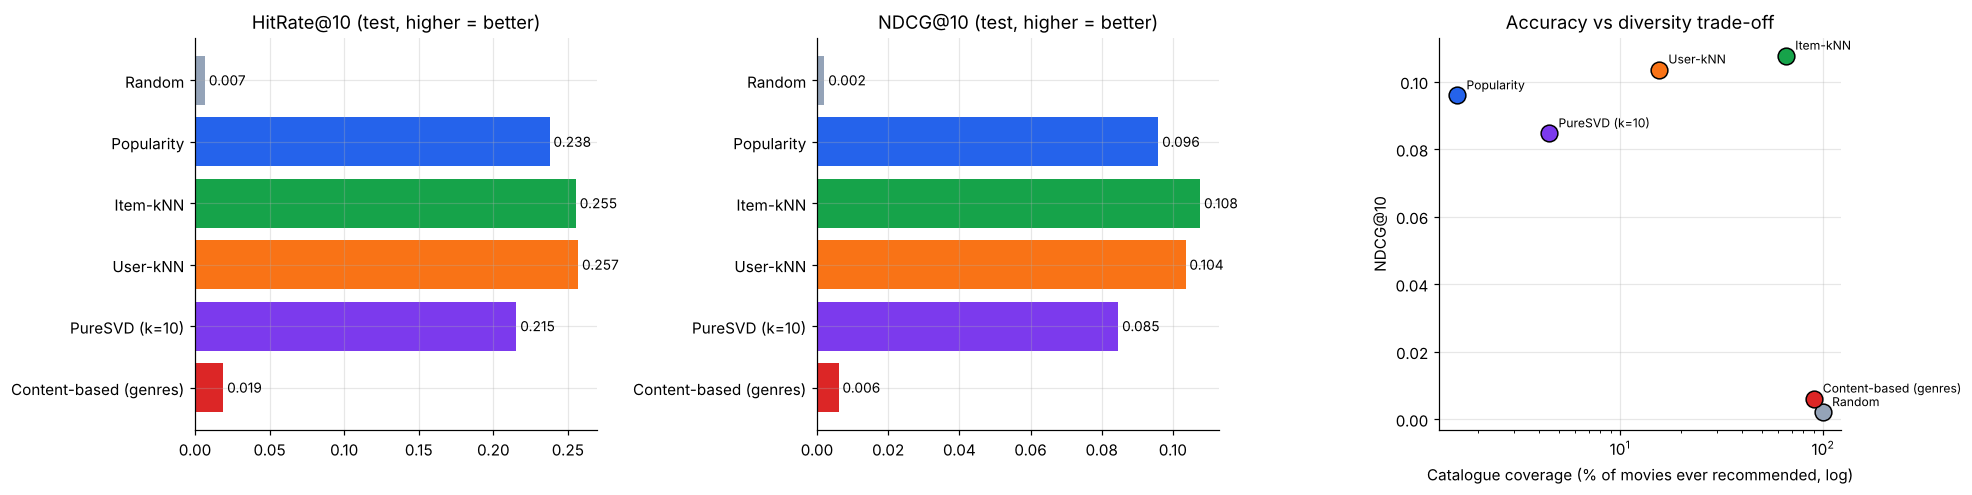

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
order = topn.model.tolist()
cols = PAL[:len(order)]
for ax, met in zip(axes[:2], ["HitRate@10", "NDCG@10"]):
    ax.barh(order[::-1], topn[met].values[::-1], color=cols[::-1])
    for j, v in enumerate(topn[met].values[::-1]): ax.text(v, j, f" {v:.3f}", va="center", fontsize=9)
    ax.set_title(met + " (test, higher = better)")
ax = axes[2]
for j, r in topn.iterrows():
    ax.scatter(r["Coverage"] * 100, r["NDCG@10"], s=120, color=cols[j], edgecolor="k", zorder=3)
    ax.annotate(r.model, (r["Coverage"] * 100, r["NDCG@10"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Catalogue coverage (% of movies ever recommended, log)"); ax.set_ylabel("NDCG@10")
ax.set_title("Accuracy vs diversity trade-off")
plt.tight_layout(); plt.savefig("figures/topn_comparison.png", bbox_inches="tight"); plt.show()

## 6. Cold start: how does accuracy depend on user history?
Users are grouped by how many movies they rated in training. Collaborative methods need history, while popularity does not.

,Popularity,Item-kNN,User-kNN,PureSVD (k=10),users
4–6,0.245,0.275,0.280,0.222,1057
7–12,0.269,0.280,0.269,0.235,1019
13–30,0.210,0.224,0.225,0.208,924
31+,0.128,0.145,0.148,0.145,345


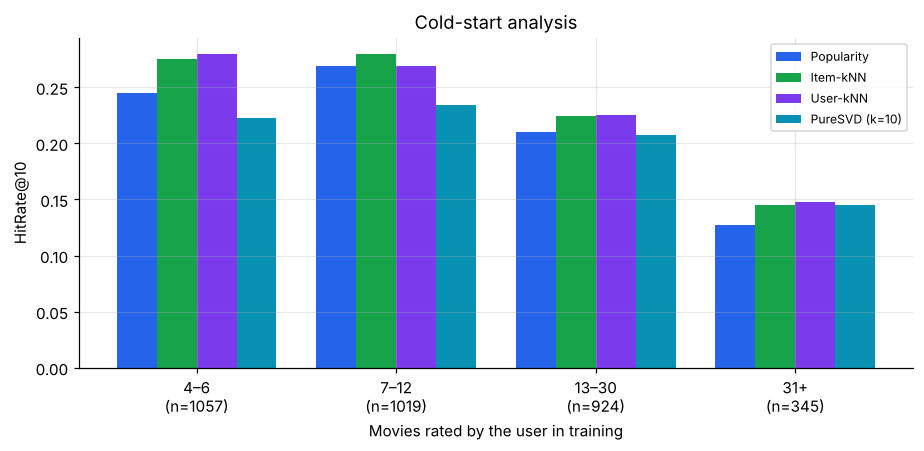

In [13]:
hist_len = np.asarray(TR[eval_users].sign().sum(1)).ravel()
bins = [(4, 6), (7, 12), (13, 30), (31, 1000)]
labels = ["4–6", "7–12", "13–30", "31+"]
cs = {m: [] for m in ["Popularity", "Item-kNN", "User-kNN", f"PureSVD (k={best_svd_k})"]}
for lo, hi in bins:
    sel = (hist_len >= lo) & (hist_len <= hi)
    for m in cs:
        hits = [any(i in set(test_rel[inv_uid[u]]) for i in tops[m][row]) for row, u in enumerate(eval_users) if sel[row]]
        cs[m].append(np.mean(hits) if hits else np.nan)
cold = pd.DataFrame(cs, index=labels); cold["users"] = [int(((hist_len >= lo) & (hist_len <= hi)).sum()) for lo, hi in bins]
display(cold.round(3))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(labels)); wdt = .2
for j, m in enumerate(cs): ax.bar(x + (j - 1.5) * wdt, cold[m], wdt, label=m, color=[PAL[1], PAL[2], PAL[4], PAL[6]][j])
ax.set_xticks(x); ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labels, cold.users)]); ax.set_xlabel("Movies rated by the user in training")
ax.set_ylabel("HitRate@10"); ax.set_title("Cold-start analysis"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/cold_start.png", bbox_inches="tight"); plt.show()
cold.to_csv("results/cold_start.csv")

## 7. Demo: recommendations and similar movies

In [14]:
title_of = movies.set_index("movie_id").title
def recommend(user_id, model="Item-kNN", n=8):
    row = int(np.where(eval_users == uid[user_id])[0][0])
    sc = S[model][row].astype(float).copy(); sc[TR[uid[user_id]].nonzero()[1]] = -np.inf
    return [title_of[inv_iid[i]] for i in np.argsort(-sc)[:n]]
demo_user = inv_uid[eval_users[np.argsort(hist_len)[len(hist_len) // 2]]]   # a typical (median-history) user
hist = trval[trval.user_id == demo_user].sort_values("rating", ascending=False).merge(movies, on="movie_id")
print(f"User {demo_user} liked:", "; ".join(hist[hist.rating >= LIKE].title.head(6)))
print("\nItem-kNN recommends:   ", "; ".join(recommend(demo_user, "Item-kNN")))
print("Popularity recommends: ", "; ".join(recommend(demo_user, "Popularity")))
print("Actually watched next (test):", "; ".join(title_of[m] + f" ({r}/10)" for m, r in test_df[test_df.user_id == demo_user][["movie_id", "rating"]].values))

User 4256 liked: Wreck-It Ralph (2012); Oblivion (2013); The Great Gatsby (2013); Man of Steel (2013); Iron Man 3 (2013); Fast & Furious 6 (2013)

Item-kNN recommends:    World War Z (2013); Now You See Me (2013); The Wolverine (2013); Oz the Great and Powerful (2013); Olympus Has Fallen (2013); G.I. Joe: Retaliation (2013); The Hangover Part III (2013); Despicable Me 2 (2013)
Popularity recommends:  World War Z (2013); Oz the Great and Powerful (2013); Now You See Me (2013); Olympus Has Fallen (2013); Silver Linings Playbook (2012); Django Unchained (2012); Argo (2012); The Hangover Part III (2013)
Actually watched next (test): The Place Beyond the Pines (2012) (8/10); Trance (2013) (8/10)


In [15]:
Bn = normalize(B, axis=0)
def similar_movies(title_query, n=6):
    cand = [m for m in inv_iid if re.search(title_query, title_of[m], re.I)]
    m = max(cand, key=lambda x: pop[iid[x]]); j = iid[m]
    sims = np.asarray((Bn[:, j].T @ Bn).todense()).ravel(); sims[j] = -1
    return title_of[m], [(title_of[inv_iid[i]], round(float(sims[i]), 3)) for i in np.argsort(-sims)[:n]]
for q in ["Gravity", "Iron Man 3", "The Conjuring"]:
    try:
        t, lst = similar_movies(q)
        print(f"\nPeople who rated '{t}' also rated:"); [print(f"   {name}  (cosine {s})") for name, s in lst]
    except ValueError:
        pass


People who rated 'Iron Man 3 (2013)' also rated:
   Star Trek Into Darkness (2013)  (cosine 0.459)
   Man of Steel (2013)  (cosine 0.456)
   Oblivion (2013)  (cosine 0.405)
   Fast & Furious 6 (2013)  (cosine 0.387)
   World War Z (2013)  (cosine 0.357)
   Pacific Rim (2013)  (cosine 0.353)

People who rated 'The Conjuring (2013)' also rated:
   The Wolverine (2013)  (cosine 0.28)
   World War Z (2013)  (cosine 0.266)
   The Purge (2013)  (cosine 0.263)
   Pacific Rim (2013)  (cosine 0.262)
   Evil Dead (2013)  (cosine 0.261)
   The Heat (2013)  (cosine 0.255)


## 8. Conclusions
* **Biases are the big win for rating prediction.** User and item biases cut RMSE from 1.79 to 1.48 (−18%, Wilcoxon p ≈ 10⁻²⁵⁷). SVD latent factors add almost nothing (1.477 → 1.476): with about 13 ratings per user there is little signal left for them to capture.
* **Item-kNN is the best top-N model.** It has the highest NDCG@10 (0.108 vs 0.096 for popularity, a statistically significant +12%) and recommends from **66% of the catalogue against 1.6% for popularity**, with clearly higher novelty. Popularity is a strong baseline on trend-driven data, but it shows everyone the same blockbusters.
* **More complex is not always better.** PureSVD scored *below* popularity, and a validation search over blends of item-kNN, user-kNN, PureSVD and popularity selected pure item-kNN, so no hybrid is reported. On very sparse data, simple neighbourhood methods are hard to beat.
* **Genres alone are not enough.** The content-based model has huge coverage but almost no accuracy, because genre labels are too coarse to capture taste. Richer metadata (cast, director, plot embeddings) would be needed.
* **Cold start:** item-kNN beats popularity in every history group. All methods get *harder* for very heavy users (31+ ratings), whose next movies tend to be niche and are therefore hard to predict.